# 07 — Model evaluation v3
Giữ nguyên split 70/15/15 và config do NB06 chọn. Không chọn feature, weight hay hyperparameter ở đây. Holdout đã được dùng ở phase trước, do đó kết quả chỉ là kiểm tra phát triển, không phải test độc lập hoàn toàn. Threshold chọn từ validation cho báo cáo nghiệp vụ, không dùng khi submission ranking.

In [1]:
from pathlib import Path
import sys, json, pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import lightgbm as lgb
import xgboost as xgb
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import average_precision_score, roc_auc_score, brier_score_loss

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "src").is_dir():
    PROJECT_ROOT = PROJECT_ROOT.parent
assert (PROJECT_ROOT / "src").is_dir(), "Run from project root or notebooks/"
sys.path.insert(0, str(PROJECT_ROOT))
from src.features import add_features, FEATURE_VERSION, FEATURE_SETS, CATEGORICAL_COLUMNS
from src.split import time_based_split, create_stratified_kfold
assert FEATURE_VERSION == "v3", "Copy features_v3.py to src/features.py and restart kernel"
DATA_DIR = PROJECT_ROOT / "data"
ARTIFACT_DIR = DATA_DIR / "artifacts"
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
RANDOM_STATE = 42
N_SPLITS = 5
N_JOBS = 4
# Use "cuda:0" on a machine with a compatible XGBoost GPU setup.
XGB_DEVICE = "cpu"

from sklearn.metrics import (precision_recall_curve, confusion_matrix, classification_report,
                             precision_score, recall_score, f1_score, PrecisionRecallDisplay, RocCurveDisplay)

In [2]:
def load_featured(kind):
    raw_path = DATA_DIR / f"{kind}.csv"
    cache_path = DATA_DIR / f"{kind}_featured_{FEATURE_VERSION}.pkl"
    required = set(FEATURE_SETS["compact_all"]) | {"id"}
    identity_cols = ["id", "is_fraud"] if kind == "train" else ["id"]
    required.update(identity_cols)
    if cache_path.exists() and cache_path.stat().st_mtime >= raw_path.stat().st_mtime:
        try:
            frame = pd.read_pickle(cache_path)
            identity = pd.read_csv(raw_path, usecols=identity_cols)
            if not required.issubset(frame.columns):
                raise ValueError("Missing v3 features")
            for col in identity_cols:
                if not np.array_equal(frame[col].to_numpy(), identity[col].to_numpy()):
                    raise ValueError(f"Cached {col} alignment mismatch")
            if not frame["id"].is_unique:
                raise ValueError("Duplicate IDs")
            print("Loaded:", cache_path.name)
            return frame.reset_index(drop=True)
        except (OSError, ImportError, AttributeError, TypeError, ValueError,
                NotImplementedError, EOFError, pickle.UnpicklingError) as exc:
            print(f"Rebuilding {cache_path.name}: {exc}")
    raw = pd.read_csv(raw_path)
    frame = add_features(raw.drop(columns="is_fraud", errors="ignore"))
    if kind == "train":
        frame["is_fraud"] = raw["is_fraud"].astype(int)
    assert frame["id"].is_unique and required.issubset(frame.columns)
    frame.to_pickle(cache_path)
    print("Saved:", cache_path.name)
    return frame.reset_index(drop=True)


def align_categories(train, *others, cat_cols):
    train = train.copy()
    others = [frame.copy() for frame in others]
    for col in cat_cols:
        # Materialize strings to ensure XGBoost-compatible categorical labels.
        train[col] = train[col].astype(object).astype("category").cat.remove_unused_categories()
        cats = train[col].cat.categories
        for frame in others:
            frame[col] = pd.Categorical(frame[col].astype(object), categories=cats)
    return (train, *others)


def split_development(frame):
    parts = time_based_split(frame, id_col="id", train_ratio=0.70,
                             valid_ratio=0.15, buffer_size=0)
    return tuple(parts[k].sort_values("id").reset_index(drop=True)
                 for k in ("train", "valid", "test_holdout"))


def scores(y, p):
    return {"AP": float(average_precision_score(y, p)),
            "ROC-AUC": float(roc_auc_score(y, p)),
            "Brier": float(brier_score_loss(y, p))}


def fixed_params(config):
    out = {"LightGBM": dict(config["lightgbm_params"]),
           "XGBoost": dict(config["xgboost_params"])}
    for params in out.values():
        params.pop("early_stopping_rounds", None)
        params.pop("callbacks", None)
        params["n_jobs"] = N_JOBS
    out["XGBoost"].update(device=XGB_DEVICE, enable_categorical=True, tree_method="hist")
    return out


def build_model(name, params):
    return (lgb.LGBMClassifier if name == "LightGBM" else xgb.XGBClassifier)(**params)

In [3]:
config_path = ARTIFACT_DIR / f"final_model_config_{FEATURE_VERSION}.json"
config = json.loads(config_path.read_text(encoding="utf-8"))
assert config["feature_version"] == FEATURE_VERSION
FEATURE_COLS = config["feature_columns"]
CAT_COLS = config["categorical_columns"]
SELECTED = config["selected_model"]
assert FEATURE_COLS == FEATURE_SETS[config["feature_set"]], "Feature set changed; rerun NB05/06"
assert CAT_COLS == [c for c in FEATURE_COLS if c in CATEGORICAL_COLUMNS]
assert SELECTED in ("LightGBM", "XGBoost", "Weighted Blending")
RANDOM_STATE = int(config["random_state"])
N_SPLITS = int(config["n_splits"])
params = fixed_params(config)
a = float(config["ensemble_weights"]["lightgbm"])
assert 0 <= a <= 1 and np.isclose(a + config["ensemble_weights"]["xgboost"], 1)
print(SELECTED, config["feature_set"], len(FEATURE_COLS), config["optimization_metric"])


def select_prediction(preds):
    if SELECTED == "Weighted Blending":
        return a * preds["LightGBM"] + (1 - a) * preds["XGBoost"]
    return preds[SELECTED]

Weighted Blending auth_risk 32 AP


In [4]:
all_df = load_featured("train")
train_df, valid_df, holdout_df = split_development(all_df)
y_train, y_valid, y_holdout = [d.is_fraud.to_numpy(dtype=int) for d in (train_df, valid_df, holdout_df)]
X_train, X_valid, X_holdout = align_categories(train_df[FEATURE_COLS], valid_df[FEATURE_COLS],
                                             holdout_df[FEATURE_COLS], cat_cols=CAT_COLS)
needed = ("LightGBM", "XGBoost") if SELECTED == "Weighted Blending" else (SELECTED,)
models = {name: build_model(name, params[name]).fit(X_train, y_train) for name in needed}
p_valid = select_prediction({name: model.predict_proba(X_valid)[:, 1] for name, model in models.items()})
p_holdout = select_prediction({name: model.predict_proba(X_holdout)[:, 1] for name, model in models.items()})
print("Validation:", scores(y_valid, p_valid), "Holdout:", scores(y_holdout, p_holdout))

Loaded: train_featured_v3.pkl
Validation: {'AP': 0.49653597760822643, 'ROC-AUC': 0.942108983233937, 'Brier': 0.011193706675616399} Holdout: {'AP': 0.5137918374785251, 'ROC-AUC': 0.9491374829928602, 'Brier': 0.01093108877447345}


In [5]:
# Choose operating threshold using validation ONLY, for a target precision.
TARGET_PRECISION = 0.80
p, r, t = precision_recall_curve(y_valid, p_valid)
# p and r have length len(t)+1; last point has no threshold.
idx = np.flatnonzero((p[:-1] >= TARGET_PRECISION) & (r[:-1] > 0))
if len(idx):
    best_i = idx[np.argmax(r[idx])]
    threshold = float(t[best_i])
    print(f"Validation threshold for precision >= {TARGET_PRECISION:.0%}: {threshold:.6f}; recall={r[best_i]:.4f}")
else:
    threshold = 0.5
    print("No nontrivial validation threshold reaches target precision; using 0.5 as illustrative fallback.")
# Save chosen threshold as reporting metadata, not as a new hyperparameter tuned on holdout.

Validation threshold for precision >= 80%: 0.657945; recall=0.2600


In [6]:
def metric_row(name, y, probabilities, threshold):
    prediction = (probabilities >= threshold).astype(int)
    return {"dataset": name,
            "PR-AUC (AP)": average_precision_score(y, probabilities),
            "ROC-AUC": roc_auc_score(y, probabilities),
            "Brier": brier_score_loss(y, probabilities),
            "Precision@threshold": precision_score(y, prediction, zero_division=0),
            "Recall@threshold": recall_score(y, prediction, zero_division=0),
            "F1@threshold": f1_score(y, prediction, zero_division=0),
            "predicted_fraud_rate": prediction.mean()}
report = pd.DataFrame([metric_row("validation", y_valid, p_valid, threshold),
                       metric_row("holdout", y_holdout, p_holdout, threshold)])
display(report.round(6))
report.to_csv(ARTIFACT_DIR / f"07_final_evaluation_metrics_{FEATURE_VERSION}.csv", index=False)
print("Confusion matrix (holdout):\n", confusion_matrix(y_holdout, p_holdout >= threshold))
print(classification_report(y_holdout, p_holdout >= threshold, digits=4, zero_division=0))

,dataset,PR-AUC (AP),ROC-AUC,Brier,Precision@threshold,Recall@threshold,F1@threshold,predicted_fraud_rate
0,validation,0.496536,0.942109,0.011194,0.800357,0.259988,0.392483,0.005343
1,holdout,0.513792,0.949137,0.010931,0.801667,0.279651,0.414655,0.005715


Confusion matrix (holdout):
 [[103155    119]
 [  1239    481]]
              precision    recall  f1-score   support

           0     0.9881    0.9988    0.9935    103274
           1     0.8017    0.2797    0.4147      1720

    accuracy                         0.9871    104994
   macro avg     0.8949    0.6392    0.7041    104994
weighted avg     0.9851    0.9871    0.9840    104994



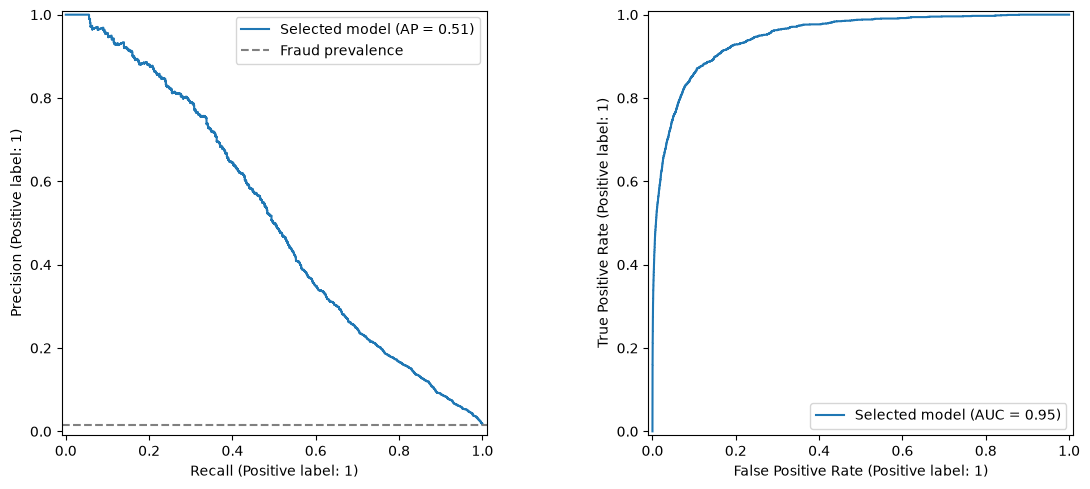

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
PrecisionRecallDisplay.from_predictions(y_holdout, p_holdout, ax=axes[0], name="Selected model")
axes[0].axhline(y_holdout.mean(), ls="--", color="grey", label="Fraud prevalence")
axes[0].legend()
RocCurveDisplay.from_predictions(y_holdout, p_holdout, ax=axes[1], name="Selected model")
plt.tight_layout()
plt.show()
# Diagnostic only: never re-select model, weight, features, or threshold using these plots.

In [8]:
holdout_errors = holdout_df[["id", "is_fraud"]].copy()
holdout_errors["fraud_probability"] = p_holdout
holdout_errors["predicted_fraud"] = (p_holdout >= threshold).astype(int)
holdout_errors["error_type"] = np.select(
    [(holdout_errors.is_fraud.eq(1) & holdout_errors.predicted_fraud.eq(0)),
     (holdout_errors.is_fraud.eq(0) & holdout_errors.predicted_fraud.eq(1))],
    ["False negative", "False positive"], default="Correct")
print(holdout_errors["error_type"].value_counts())
display(holdout_errors.sort_values("fraud_probability", ascending=False).head(10))
# Keep this error-analysis CSV private if IDs are sensitive.
holdout_errors.to_csv(ARTIFACT_DIR / f"07_holdout_predictions_{FEATURE_VERSION}.csv", index=False)
(ARTIFACT_DIR / f"07_evaluation_metadata_{FEATURE_VERSION}.json").write_text(
    json.dumps({"selected_model": SELECTED, "target_precision": TARGET_PRECISION,
                "validation_chosen_threshold": threshold, "holdout_pr_auc": float(average_precision_score(y_holdout, p_holdout)),
                "holdout_has_been_used_in_earlier_experiments": True}, indent=2), encoding="utf-8")

error_type
Correct           103636
False negative      1239
False positive       119
Name: count, dtype: int64


,id,is_fraud,fraud_probability,predicted_fraud,error_type
2058,597024,1,0.997522,1,Correct
74283,669249,1,0.996873,1,Correct
45773,640739,1,0.996858,1,Correct
102394,697360,1,0.996630,1,Correct
63040,658006,1,0.995409,1,Correct
10594,605560,1,0.995203,1,Correct
23875,618841,1,0.993089,1,Correct
62165,657131,1,0.992530,1,Correct
103777,698743,1,0.992490,1,Correct
99066,694032,1,0.992406,1,Correct


219